Ali khabazian - 402416066 / exercise 7 - critical phenomena - question 3, part b

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
d = 3  # Change d to 3 for d < 4, or d > 4 to test answers
epsilon = 4 - d  

In [3]:
def du(u, v):
    return (epsilon - 4 * (d + 8)) * u - 24 * v

def dv(u, v):
    return -48 * u + (epsilon - 36) * v

In [4]:
u = np.linspace(-2, 2, 20)  
v = np.linspace(-2, 2, 20)  
U, V = np.meshgrid(u, v)

In [5]:
dU = du(U, V)
dV = dv(U, V)

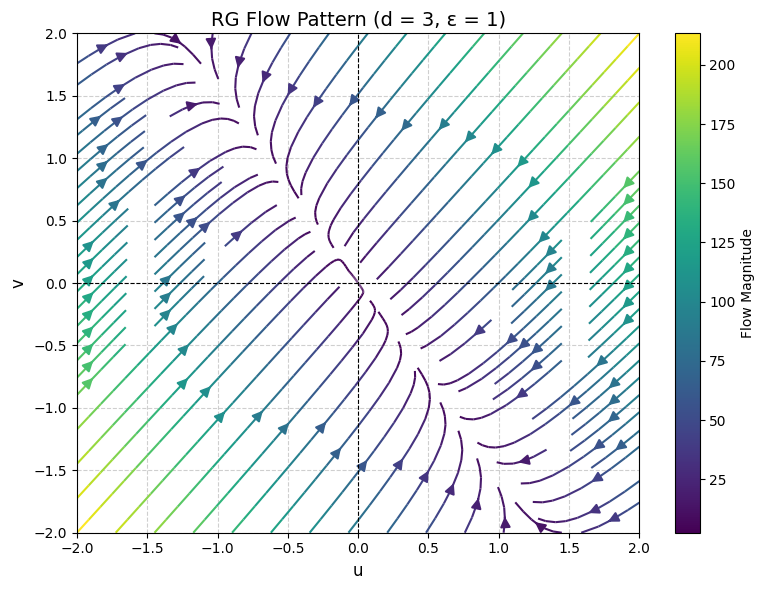

In [6]:
plt.figure(figsize=(8, 6))
plt.streamplot(U, V, dU, dV, color=np.sqrt(dU**2 + dV**2), cmap='viridis', arrowsize=1.5)
plt.title(f"RG Flow Pattern (d = {d}, ε = {epsilon})", fontsize=14)
plt.xlabel("u", fontsize=12)
plt.ylabel("v", fontsize=12)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')  # Horizontal
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')  # Vertical 
plt.colorbar(label="Flow Magnitude")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()

#second approach

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

In [2]:
def vector_field(U, V, d):
    
    epsilon = 4 - d
    
    du = (epsilon - 4*(d + 8)*U)*U - 24*U*V
    dv = -48*V*U + (epsilon - 36*V)*V
    
    return du, dv

In [3]:
def create_streamplot(d, ax, title):
    """Create a streamplot for a given value of d"""
    
    u = np.linspace(-0.5, 0.5, 30)
    v = np.linspace(-0.5, 0.5, 30)
    U, V = np.meshgrid(u, v)
    
    dU, dV = vector_field(U, V, d)
    
    magnitude = np.sqrt(dU**2 + dV**2)
    dU = dU / (magnitude + 1e-10)
    dV = dV / (magnitude + 1e-10)
    
    ax.streamplot(U, V, dU, dV, density=1.5, color='blue', linewidth=1)
    ax.plot(0, 0, 'ro', label='Origin (0,0)')
    ax.set_xlabel('u')
    ax.set_ylabel('v')
    ax.set_title(f'd = {d} (ε = {4-d:.1f})')
    ax.grid(True)
    ax.legend()

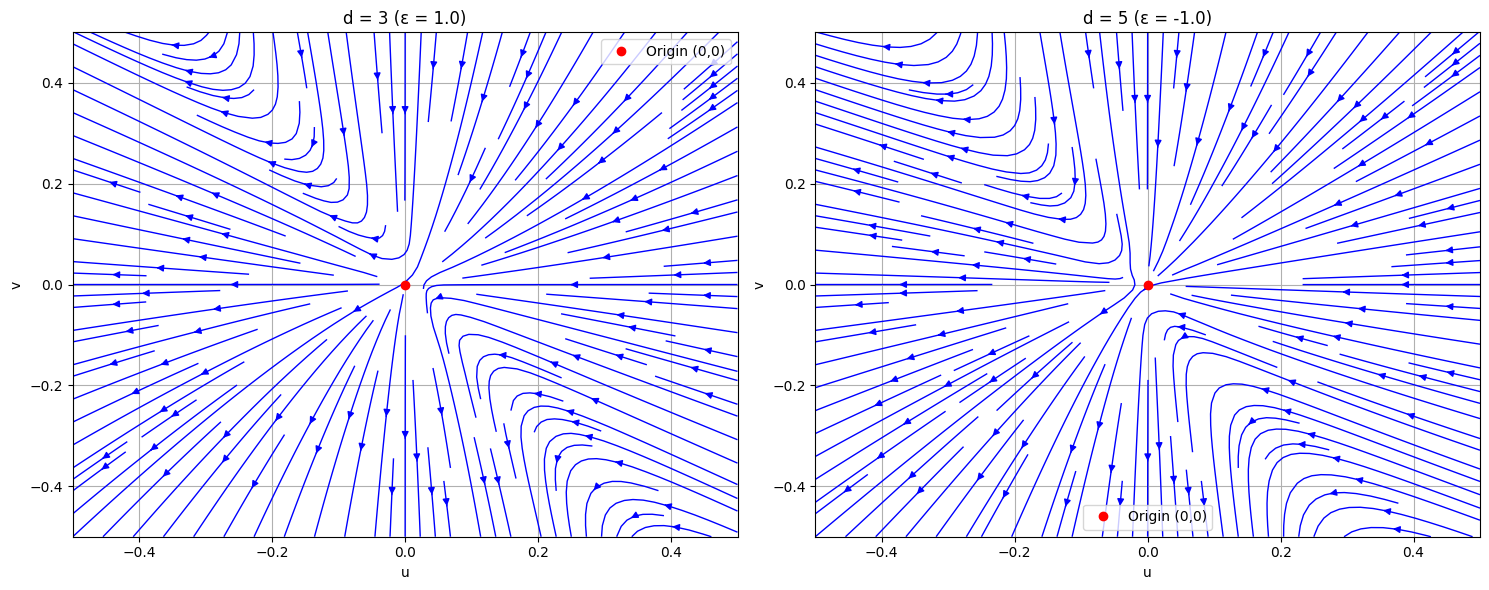

In [4]:
fig = plt.figure(figsize=(15, 6))
gs = GridSpec(1, 2, figure=fig)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

# Create stream plots for d < 4 and d > 4
create_streamplot(3, ax1, 'd < 4')
create_streamplot(5, ax2, 'd > 4')

plt.tight_layout()
plt.show()